# Лабораторная работа №1 — Wine Quality

Предсказываем оценку вина по физико-химическим показателям. Сравним baseline, линейную регрессию, Random Forest, обычный Gradient Boosting и CatBoost.

Основная метрика — RMSE, дополнительная — MAE

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from catboost import CatBoostRegressor
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.2
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

## 1. Загрузка и проверка данных

Используем набор белых вин из [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). Если CSV лежит рядом с ноутбуком, он загрузится локально; иначе попробуем скачать его с сайта UCI.

In [2]:
DATA_PATH = Path("winequality-white.csv")
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH, sep=";")
else:
    df_raw = pd.read_csv(DATA_URL, sep=";")

print(f"Размер исходного датасета: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов")
print("Пропусков:", int(df_raw.isna().sum().sum()))
print("Полностью одинаковых строк:", int(df_raw.duplicated().sum()))
display(df_raw.head())

Размер исходного датасета: 4898 строк, 12 столбцов
Пропусков: 0
Полностью одинаковых строк: 937


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.000,0.270,0.360,20.700,0.045,45.000,170.000,1.001,3.000,0.450,8.800,6
1,6.300,0.300,0.340,1.600,0.049,14.000,132.000,0.994,3.300,0.490,9.500,6
2,8.100,0.280,0.400,6.900,0.050,30.000,97.000,0.995,3.260,0.440,10.100,6
3,7.200,0.230,0.320,8.500,0.058,47.000,186.000,0.996,3.190,0.400,9.900,6
4,7.200,0.230,0.320,8.500,0.058,47.000,186.000,0.996,3.190,0.400,9.900,6


В датасете есть полностью одинаковые строки. Оставим по одной копии каждой такой строки, чтобы одинаковые записи не оказались одновременно в обучении и тесте. Остальные данные не меняем.

In [3]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"После удаления полных дублей: {len(df)} строк")
display(df["quality"].describe().to_frame().T)

После удаления полных дублей: 3961 строк


,count,mean,std,min,25%,50%,75%,max
quality,3961.000,5.855,0.891,3.000,5.000,6.000,6.000,9.000


## 2. Короткий анализ данных

Сначала посмотрим, какие оценки встречаются чаще всего.

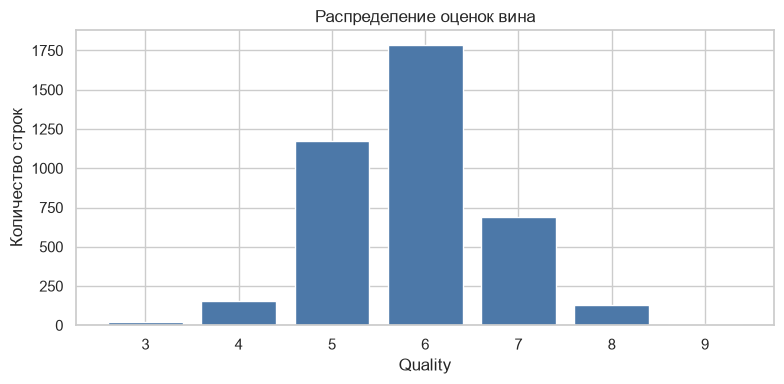

In [4]:
quality_counts = df["quality"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(quality_counts.index.astype(str), quality_counts.values, color="#4C78A8")
ax.set(title="Распределение оценок вина", xlabel="Quality", ylabel="Количество строк")
plt.tight_layout()
plt.show()

Большинство вин получает оценки около 5–7. Крайних оценок заметно меньше, поэтому по ним модель будет учиться на меньшем количестве примеров.

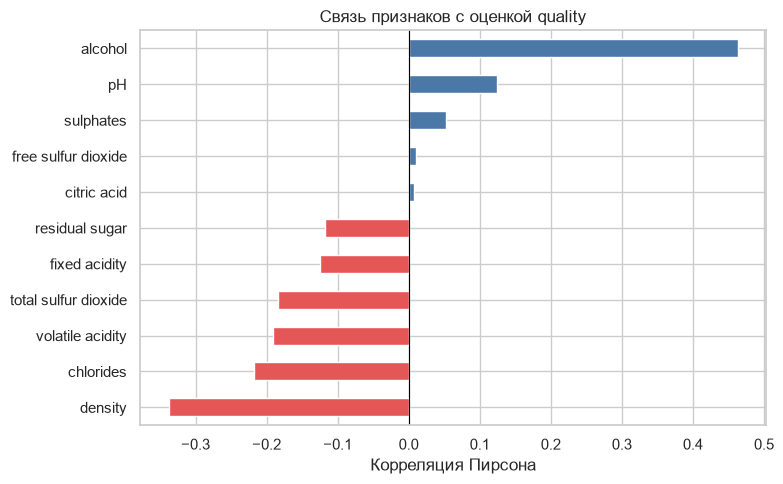

,Корреляция с quality
alcohol,0.463
pH,0.124
sulphates,0.053
free sulfur dioxide,0.011
citric acid,0.007
residual sugar,-0.117
fixed acidity,-0.125
total sulfur dioxide,-0.183
volatile acidity,-0.191
chlorides,-0.218


In [5]:
quality_corr = df.corr(numeric_only=True)["quality"].drop("quality").sort_values()
colors = ["#E45756" if value < 0 else "#4C78A8" for value in quality_corr]

fig, ax = plt.subplots(figsize=(8, 5))
quality_corr.plot(kind="barh", color=colors, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Связь признаков с оценкой quality", xlabel="Корреляция Пирсона", ylabel="")
plt.tight_layout()
plt.show()

display(quality_corr.to_frame(name="Корреляция с quality").sort_values("Корреляция с quality", ascending=False).round(3))

У `alcohol` обычно заметна положительная связь с оценкой, а у `volatile acidity` и `density` — отрицательная. Связь не означает, что одного показателя достаточно для хорошего прогноза: оценка зависит сразу от нескольких характеристик, а часть зависимостей может быть нелинейной.

## 3. Разбиение данных и кросс-валидация

Оставим 20% данных для финальной проверки. При разбиении используем `stratify=y`: значения `quality` дискретные, поэтому можно сохранить примерно те же доли оценок в train и test.

На обучающей части сравним модели с помощью `StratifiedKFold`. Число фолдов выбираем по размеру самого редкого класса, чтобы в каждом фолде хватило наблюдений. Тестовую выборку при выборе модели не используем.

In [6]:
X = df.drop(columns="quality")
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

n_splits = min(5, int(y_train.value_counts().min()))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {len(X_train)} строк ({len(X_train) / len(X):.0%})")
print(f"Test:  {len(X_test)} строк ({len(X_test) / len(X):.0%})")
print(f"StratifiedKFold: {n_splits} фолда")

Train: 3168 строк (80%)
Test:  793 строк (20%)
StratifiedKFold: 4 фолда


## 4. Метрики и модели

`MAE` — средняя абсолютная ошибка в баллах `quality`. `RMSE` тоже измеряется в баллах, но сильнее реагирует на большие ошибки.

Для baseline используем среднюю оценку на обучающей выборке. Остальные модели сравним по среднему RMSE на одинаковых фолдах. Параметры оставим умеренными: данных около четырёх тысяч строк, поэтому слишком глубокие деревья могут переобучиться.

In [43]:
def get_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return {"RMSE": rmse, "MAE": mae}


models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_features=0.8,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=250,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=4,
        subsample=0.9,
        random_state=RANDOM_STATE,
    ),
    "CatBoost": CatBoostRegressor(
        iterations=800,
        learning_rate=0.03,
        depth=5,
        l2_leaf_reg=5,
        loss_function="RMSE",
        random_seed=RANDOM_STATE,
        verbose=0,
        thread_count=-1,
    ),
}

cv_rows = []
for name, model in models.items():
    fold_scores = []

    for train_idx, valid_idx in cv.split(X_train, y_train):
        fold_model = clone(model)
        fold_model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        pred = fold_model.predict(X_train.iloc[valid_idx])
        fold_scores.append(np.sqrt(mean_squared_error(y_train.iloc[valid_idx], pred)))

    cv_rows.append({
        "Модель": name,
        "Средний CV RMSE": np.mean(fold_scores),
        "Разброс по фолдам": np.std(fold_scores),
    })

cv_results = (
    pd.DataFrame(cv_rows)
    .set_index("Модель")
    .sort_values("Средний CV RMSE")
)
display(cv_results.round(3))

,Средний CV RMSE,Разброс по фолдам
Модель,,
CatBoost,0.705,0.013
Random Forest,0.706,0.015
Gradient Boosting,0.715,0.012
Linear Regression,0.746,0.006
Baseline,0.891,0.001


## 5. Итоговое сравнение на test

По среднему RMSE на кросс-валидации выбираем модель. Затем обучаем модели на всей train-части и сравниваем их на test. Эти результаты нужны для финальной оценки, а не для повторного подбора параметров.

In [44]:
best_model_name = cv_results.drop(index="Baseline").index[0]

for model in models.values():
    model.fit(X_train, y_train)

predictions = {
    name: model.predict(X_test)
    for name, model in models.items()
}

results = pd.DataFrame({
    name: get_metrics(y_test, pred)
    for name, pred in predictions.items()
}).T
results.index.name = "Модель"
results["Лучше baseline"] = results["RMSE"] < results.loc["Baseline", "RMSE"]
results = results.sort_values("RMSE")

display(results.round(3))

print(f"Лучшая модель по CV: {best_model_name}")
print(f"CV RMSE: {cv_results.loc[best_model_name, 'Средний CV RMSE']:.3f}")
print(f"Test RMSE: {results.loc[best_model_name, 'RMSE']:.3f}")

,RMSE,MAE,Лучше baseline
Модель,,,
Random Forest,0.693,0.539,True
CatBoost,0.695,0.545,True
Gradient Boosting,0.711,0.558,True
Linear Regression,0.761,0.587,True
Baseline,0.891,0.679,False


Лучшая модель по CV: CatBoost
CV RMSE: 0.705
Test RMSE: 0.695


## 6. Коэффициенты линейной регрессии

Перед обучением признаки стандартизованы, поэтому коэффициенты можно сравнивать по модулю. Знак показывает направление связи в рамках линейной модели, но не причинный эффект.

In [45]:
linear_coefficients = pd.Series(
    models["Linear Regression"].named_steps["model"].coef_,
    index=X.columns,
    name="Коэффициент",
)
coefficient_table = pd.DataFrame({
    "Коэффициент": linear_coefficients,
    "Модуль": linear_coefficients.abs(),
}).sort_values("Модуль", ascending=False)

display(coefficient_table.drop(columns="Модуль").head(6).round(3))

,Коэффициент
density,-0.560
residual sugar,0.431
alcohol,0.169
volatile acidity,-0.165
pH,0.150
fixed acidity,0.086


## 7. Важность признаков

Сравним важность признаков у Random Forest, Gradient Boosting и CatBoost на одном графике. Небольшие различия между моделями нормальны: они по-разному строят деревья и уменьшают ошибку.

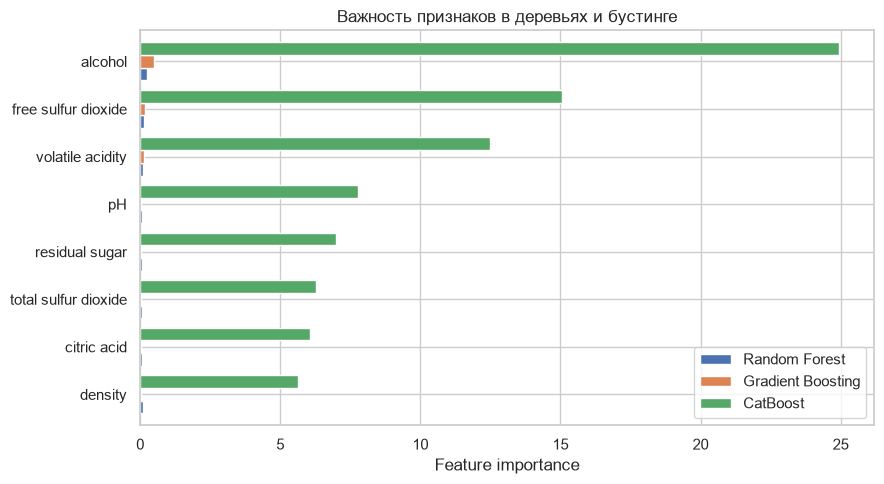

,Random Forest,Gradient Boosting,CatBoost,Средняя
alcohol,0.233,0.494,24.941,8.556
free sulfur dioxide,0.121,0.170,15.066,5.119
volatile acidity,0.110,0.140,12.496,4.249
pH,0.074,0.032,7.780,2.629
residual sugar,0.065,0.028,7.001,2.365
total sulfur dioxide,0.067,0.022,6.265,2.118
citric acid,0.057,0.029,6.044,2.043
density,0.093,0.016,5.648,1.919
sulphates,0.060,0.013,5.324,1.799
chlorides,0.061,0.035,5.113,1.736


In [46]:
tree_model_names = ["Random Forest", "Gradient Boosting", "CatBoost"]
importance = pd.DataFrame(
    {
        name: models[name].feature_importances_
        for name in tree_model_names
    },
    index=X.columns,
)

top_features = importance.mean(axis=1).nlargest(8).index
ax = importance.loc[top_features].sort_values("CatBoost").plot(
    kind="barh", figsize=(9, 5), width=0.8
)
ax.set(title="Важность признаков в деревьях и бустинге", xlabel="Feature importance", ylabel="")
plt.tight_layout()
plt.show()

display(importance.assign(Средняя=importance.mean(axis=1)).sort_values("Средняя", ascending=False).round(3))

Важность показывает, какие признаки модель чаще использовала для снижения ошибки. Это не доказывает, что изменение такого признака само по себе меняет оценку: показатели могут быть связаны между собой, а в данных нет всех факторов, которые учитывает дегустатор.

## 8. Ошибки лучшей модели

Посмотрим, где модель ошибается сильнее всего и как качество зависит от реальной оценки вина. Для выбора модели использовали кросс-валидацию; test оставили для итоговой проверки.

Модель: CatBoost
RMSE = 0.695; MAE = 0.545


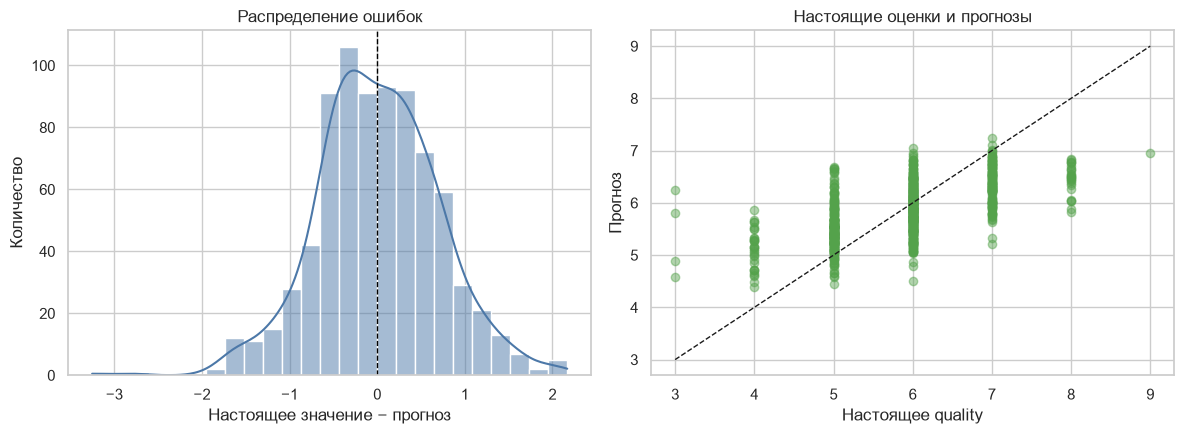

In [47]:
best_model = models[best_model_name]
best_pred = predictions[best_model_name]
residuals = y_test.to_numpy() - best_pred

print(f"Модель: {best_model_name}")
print(f"RMSE = {results.loc[best_model_name, 'RMSE']:.3f}; MAE = {results.loc[best_model_name, 'MAE']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(residuals, bins=25, kde=True, ax=axes[0], color="#4C78A8")
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Распределение ошибок", xlabel="Настоящее значение − прогноз", ylabel="Количество")

axes[1].scatter(y_test, best_pred, alpha=0.45, color="#54A24B")
limits = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[1].plot(limits, limits, "k--", linewidth=1)
axes[1].set(title="Настоящие оценки и прогнозы", xlabel="Настоящее quality", ylabel="Прогноз")
plt.tight_layout()
plt.show()

In [48]:
error_frame = pd.DataFrame({
    "quality": y_test.to_numpy(),
    "prediction": best_pred,
    "residual": residuals,
})
error_frame["abs_error"] = error_frame["residual"].abs()
error_frame["squared_error"] = error_frame["residual"] ** 2

error_by_quality = error_frame.groupby("quality").agg(
    n=("abs_error", "size"),
    MAE=("abs_error", "mean"),
    MSE=("squared_error", "mean"),
)
error_by_quality["RMSE"] = np.sqrt(error_by_quality.pop("MSE"))
display(error_by_quality.round(3))

worst = X_test.copy()
worst["Настоящее quality"] = y_test
worst["Прогноз"] = best_pred
worst["Абсолютная ошибка"] = np.abs(residuals)
columns_to_show = [
    "Настоящее quality", "Прогноз", "Абсолютная ошибка",
    "alcohol", "volatile acidity", "density", "residual sugar", "chlorides",
]
display(worst.nlargest(5, "Абсолютная ошибка")[columns_to_show].round(3))

,n,MAE,RMSE
quality,,,
3,4,2.384,2.477
4,31,1.113,1.174
5,235,0.528,0.646
6,358,0.369,0.452
7,138,0.650,0.746
8,26,1.544,1.570
9,1,2.040,2.040


,Настоящее quality,Прогноз,Абсолютная ошибка,alcohol,volatile acidity,density,residual sugar,chlorides
1037,3,6.253,3.253,12.400,0.330,0.991,1.150,0.033
2535,3,5.799,2.799,10.100,0.200,0.995,9.500,0.041
215,8,5.831,2.169,9.600,0.260,0.994,1.100,0.040
2097,8,5.877,2.123,10.400,0.170,0.995,8.100,0.121
732,9,6.960,2.040,12.700,0.360,0.990,4.200,0.018


В таблице по оценкам важен столбец `n`: для редких оценок метрики могут сильно меняться даже из-за одной строки. Самые большие ошибки полезно смотреть отдельно, но по одним химическим показателям не всегда можно объяснить экспертную оценку — в датасете нет данных о сорте винограда, производителе и условиях дегустации.

## 9. Итог

In [49]:
best_cv_rmse = cv_results.loc[best_model_name, "Средний CV RMSE"]
best_test_rmse = results.loc[best_model_name, "RMSE"]
best_test_mae = results.loc[best_model_name, "MAE"]
baseline_test_rmse = results.loc["Baseline", "RMSE"]
improvement = 100 * (baseline_test_rmse - best_test_rmse) / baseline_test_rmse

print(f"Лучшая модель по CV: {best_model_name}")
print(f"CV RMSE: {best_cv_rmse:.3f}")
print(f"Test RMSE: {best_test_rmse:.3f}; test MAE: {best_test_mae:.3f}")

Лучшая модель по CV: CatBoost
CV RMSE: 0.705
Test RMSE: 0.695; test MAE: 0.545
